## A loop of your own

An `Engine` is an account at a venue for a loop the caller owns, stepped one bar at a time,
with the verbs and state a Strategy's account has. Here two of them, on Bybit's Bitcoin
perpetuals settled in USDT and in USDC, step together over 2025's hourly bars: short where
the last funding rate is higher, long where it is lower, so the two legs offset in price and
the account collects the difference. `combine` then adds the two accounts into one book.

In [1]:
import pathlib

import exchange_router
import matplotlib.pyplot
import matplotlib.ticker
import numpy
import pandas
import probatum

matplotlib.pyplot.style.use(style="../oceano.mplstyle")

print(f"probatum {probatum.__version__}, exchange-router {exchange_router.__version__}")

probatum 3.0.0, exchange-router 3.3.0


### The bars of both contracts

Each contract's hourly bars with its funding, fetched once into `bars/` and cut to 2025.

In [2]:
PERP = pathlib.Path("../bars/bybit-linear-btcusdt-ethusdt-1h-2024-2025")
USDC = pathlib.Path("../bars/bybit-linear-btcusdc-1h-2025")

if PERP.exists():
    perp = probatum.Data.load(path=PERP)
else:
    with exchange_router.Router.local(exchanges=["bybit"]) as router:
        perp = probatum.Data.from_router(router, exchange="bybit", market="linear",
                                         interval="1h", symbols=["BTCUSDT", "ETHUSDT"],
                                         start="2024-01-01", end="2025-12-31", funding=True)
    perp.save(path=PERP)

if USDC.exists():
    usdc = probatum.Data.load(path=USDC)
else:
    with exchange_router.Router.local(exchanges=["bybit"]) as router:
        usdc = probatum.Data.from_router(router, exchange="bybit", market="linear",
                                         interval="1h", symbols=["BTCUSDC"],
                                         start="2025-01-01", end="2025-12-31", funding=True)
    usdc.save(path=USDC)

usdt = perp["BTCUSDT"].after(when="2025-01-01")

print(usdt, usdt.instruments[0].settlement)
print(usdc, usdc.instruments[0].settlement)
print(f"one clock: {numpy.array_equal(usdt.time, usdc.time)}")

Data(BTCUSDT, 1h, 8760 bars from 2025-01-01 00:00 to 2025-12-31 23:00) USDT
Data(BTCUSDC, 1h, 8760 bars from 2025-01-01 00:00 to 2025-12-31 23:00) USDC
one clock: True


### The loop

Each step fills on the next bar what was decided at the last close, and returns that bar.
A side is taken only where the two rates are more than half a basis point apart, and kept
until they cross that far the other way.

In [3]:
in_usdt = probatum.Engine(usdt, venue="bybit_perp")
in_usdc = probatum.Engine(usdc, venue="bybit_perp")

left, right = in_usdt.reset(), in_usdc.reset()
side, turns = 0.0, 0

while not in_usdt.done():
    gap    = left.funding_rate - right.funding_rate
    wanted = -1.0 if gap > 0.00005 else 1.0 if gap < -0.00005 else side

    if wanted != side:
        in_usdt.target(weights=0.5 * wanted)
        in_usdc.target(weights=-0.5 * wanted)
        side, turns = wanted, turns + 1

    left, right = in_usdt.step(), in_usdc.step()

print(f"{turns} turns over {len(usdt):,} bars")

59 turns over 8,760 bars


### One book of two accounts

Each account is margined on its own, and no capital moves between them; the book's equity is
their sum, its statistics those of the sum. `settlement` names the dollar the book is kept
in, the other counted at par.

In [4]:
book = probatum.combine({"BTCUSDT": in_usdt.result(), "BTCUSDC": in_usdc.result()},
                        settlement="USDT")

book

,run,buy_and_hold,low,high,level,method,why_none
total_return_pct,-4.53,-13.22,,,,,1
cagr_pct,-4.53,-13.22,,,,,1
volatility_pct,2.45,45.59,,,,,1
sharpe,-1.88,-0.08,-3.85,0.09,0.95,"delta method, Newey-West lag 10, floored at lag zero",
max_drawdown_pct,5.65,36.61,,,,,1
exposure_pct,99.19,,,,,,
num_trades,116,,,,,,
win_rate,0.49,,0.40,0.58,0.95,percentile bootstrap of round trips,
profit_factor,0.90,,0.52,1.54,0.95,BCa bootstrap of round trips,
costs,657,,,,,,


### What each account kept and paid

Each account's closing equity and the totals of its costs, in the dollar it settles in,
funding among them, a negative sum being funding received.

In [5]:
accounts = {"BTCUSDT": in_usdt.result(), "BTCUSDC": in_usdc.result()}

pandas.DataFrame({name: {"equity": run.equity[-1], **run.costs}
                  for name, run in accounts.items()}).T.round(decimals=2)

,equity,fees,funding,spread,slippage,impact,liquidation,dust
BTCUSDT,10286.29,337.89,8.72,0.0,58.16,0.97,0.0,0.0
BTCUSDC,8808.10,285.80,-93.26,0.0,49.33,9.85,0.0,0.0


### The two accounts and the book

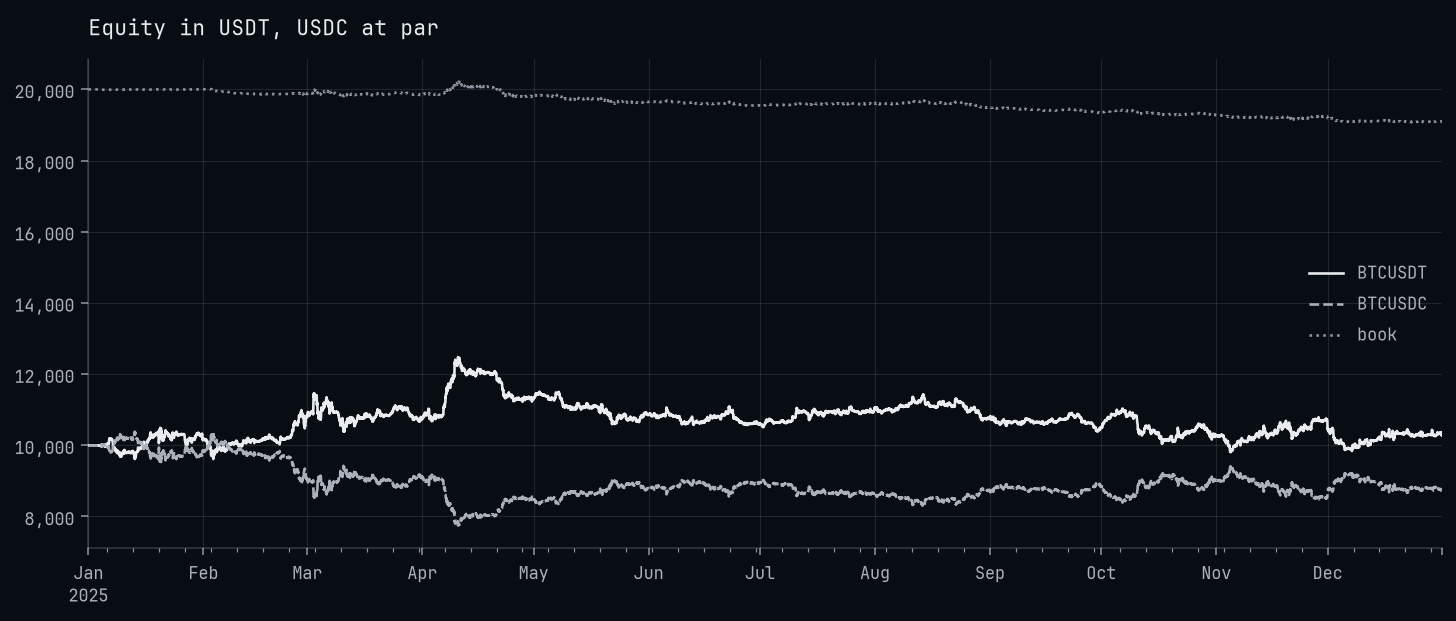

In [6]:
equity = pandas.DataFrame({name: run.equity for name, run in accounts.items()},
                          index=pandas.to_datetime(usdt.time, utc=True))
equity["book"] = book.equity[-len(equity):]

axes = equity.plot(title="Equity in USDT, USDC at par", xlabel="")
axes.yaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter(fmt="{x:,.0f}"))
matplotlib.pyplot.show()